## Something in the Way: Deep Learning for Crater Detection and Crater-Aware Route Planning on Mars
CSC 383 Final Project Notebook File\
Enes Demirel\
Instructor: Vincent Kurtz

Since the dawn of humanity, people have been asking the same question: *"What is up there?"* In 2026, we do have some answers to this question; however, the big picture remains unanswered. As the most habitable planet in our solar system after Earth, Mars has long attracted humanity. Unfortunately, we are not yet able to send humans there, so we need to do our exploration with rovers. Since it takes approximately 4 to 22 minutes for a signal to reach Mars, steering a rover in real time is not feasible. Therefore, rovers need to learn how to drive themselves autonomously. For a rover to drive autonomously, it is very important to be able to identify dangers on its own, such as craters.

In this project, we are going to try to answer two questions:

1. **What type of model would be best for identifying craters from satellite images of Mars?**
   - a) A model trained from scratch (**U-Net**)
   - b) A fine-tuned model (**Faster R-CNN**)
   - c) A foundation model (**DINOv3**)

Note: We are also going to use a a basic MLP and a basic CNN to have some baseline scores.



2. **How well would two different rovers plan their paths using the best model (Faster R-CNN), and do the craters it misses matter?:**
   - a) **Rover 1:** A rover that plans its whole path from the start with using A*
   - b) **Rover2:** A rover that uses a small neural network to predict the best move at each step from what it sees around it.


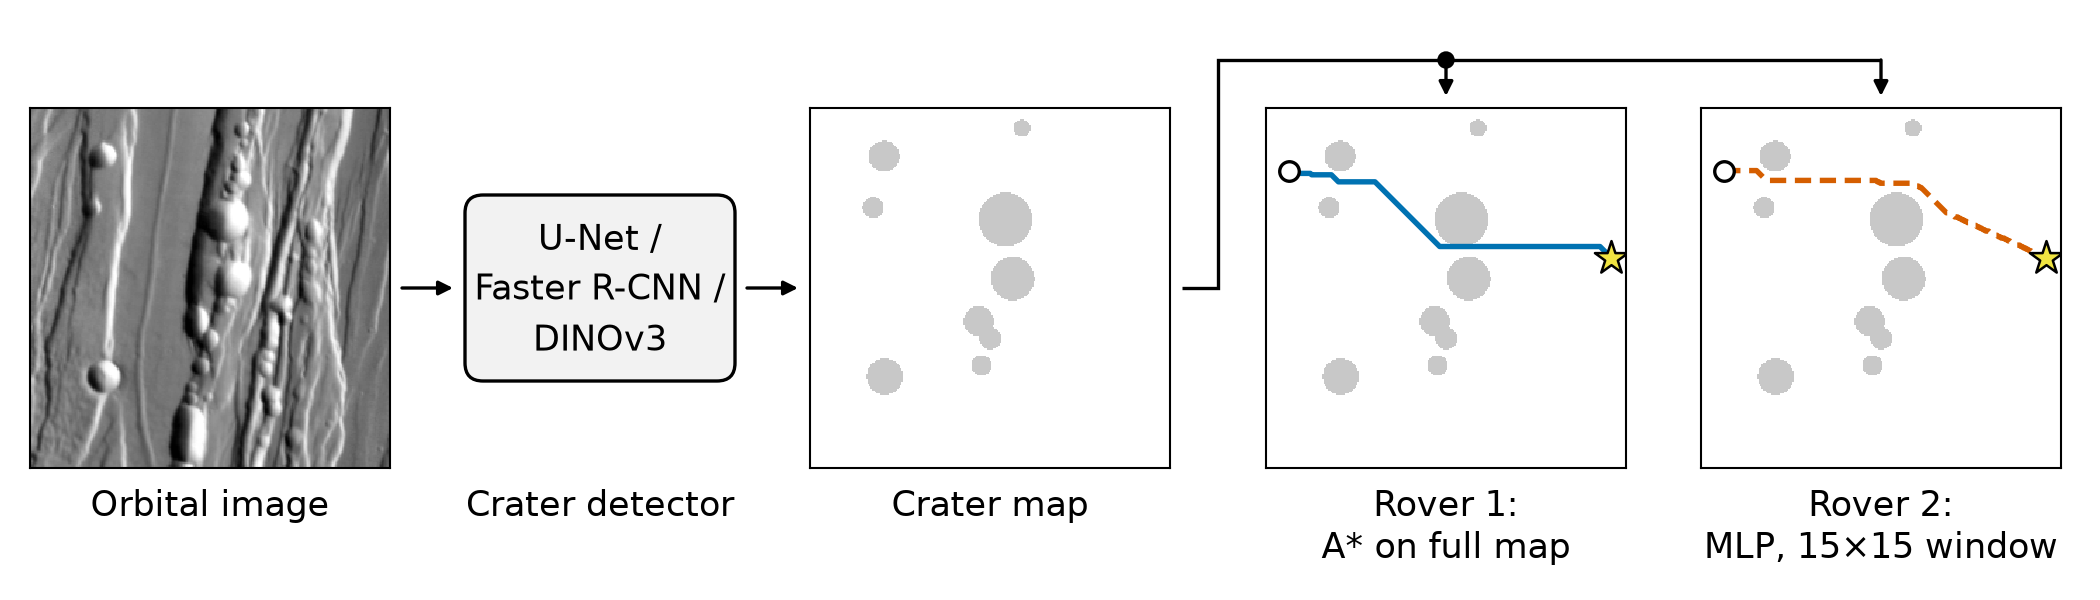

## Imports

**Basic machine learning essentials:** `numpy`, `matplotlib`, `PIL`, `tqdm`, `scikit-learn` (`train_test_split`), and `torch` (`nn`, `F`, `Dataset`, `DataLoader`, `TensorDataset`), `pandas`

**Python standard library:**
- `json`: reads the crater labels and saves the results.
- `random`: sets a fixed seed so the results can be repeated.
- `time`: measures how long each epoch takes.
- `pathlib`: builds the file paths to the images and saved models.

**Project-specific:**
- `heapq`: priority queue for the A* search (Rover 1).
- `Rectangle`: draws crater boxes on images.
- `scipy.ndimage`: finds connected crater blobs in a mask so each blob becomes one box.
- `fasterrcnn_resnet50_fpn`, `FastRCNNPredictor`: the pretrained Faster R-CNN and its new 2-class head (crater / background).
- `box_iou`: overlap between two boxes, used to match predicted craters with true craters.
- `AutoModel` (Hugging Face `transformers`): loads the pretrained DINOv3 backbone.

In [52]:
import json
import random
import time
import heapq
from pathlib import Path

import numpy as np
import matplotlib.pyplot as plt
from matplotlib.patches import Rectangle
from PIL import Image
from scipy import ndimage
from sklearn.model_selection import train_test_split
from tqdm import tqdm
import pandas as pd

import torch
from torch import nn
import torch.nn.functional as F
from torch.utils.data import Dataset, DataLoader, TensorDataset

from torchvision.models.detection import fasterrcnn_resnet50_fpn
from torchvision.models.detection.faster_rcnn import FastRCNNPredictor
from torchvision.ops import box_iou

from transformers import AutoModel

## Fixed seeds so the results can be repeated, and checking if either "GPU" or "MPS" (Apple) is available for torch.

In [5]:
torch.manual_seed(0)
random.seed(0)

if torch.cuda.is_available():
    device = "cuda"
elif torch.backends.mps.is_available():
    device = "mps"
else:
    device = "cpu"
print("Using device:", device)

Using device: cuda


## Data

**Where the dataset comes from:** The dataset is from the 2022 GeoAI Martian Challenge by the ASU CICI Lab (Hsu et al., 2021). the crater labels come from the Robbins and Hynek (2012) crater catalog. It can be downloaded from https://cici.lab.asu.edu/martian/.

**Each image:**
- a 256 × 256 grayscale image
- its labels are stored in `dataset/gt_public.json` as a list of boxes, one per crater, in the format `[x, y, width, height]`

**Cleaning:** The raw data had images with no labels (the test data). We removed them because they can't be used for training or scoring a model. We have 51,838 images left.

In [6]:
# Import the json file with labels in it.
data = json.loads(Path('dataset/gt_public.json').read_text())

assert isinstance(data, dict)
assert len(data) == 51838

In [19]:
# Delete images without any labels
images_path = Path('dataset/images')
deleted = 0
for path in images_path.rglob('*'):
    if path.is_file():
        if path.name[0:6] not in data.keys():
            path.unlink(missing_ok=True)
            deleted += 1
            
print(f"Deleted: 50837 images") # I am using a hardcoded number here because it currently shows 0. This number is the exact number of images that were deleted.
assert sum(1 for item in images_path.iterdir() if item.is_file()) == 51838

Deleted: 50837 images


## Train / validation / test split

We use an 80/10/10 rule for the training, validation and test split.

- **Train:** fits the model.
- **Validation:** picks the best epoch and the best cutoff.
- **Test:** used at the end to test the models on images they have never seen.

Total number of images: **51,838**

- a) Training: **41,470** (80%)
- b) Validation: **5,184** (10%)
- c) Test: **5,184** (10%)

In [20]:
images_path = Path("dataset/images")
data = json.loads(Path("dataset/gt_public.json").read_text())

image_ids = list(data.keys())
train_ids, rest_ids = train_test_split(image_ids, test_size=0.2, random_state=0)
val_ids, test_ids = train_test_split(rest_ids, test_size=0.5, random_state=0)

print(f"Train: {len(train_ids)}, Val: {len(val_ids)}, Test: {len(test_ids)}")

Train: 41470, Val: 5184, Test: 5184


## Crater masks

Every model except Faster R-CNN predicts crater / no crater for each pixel. Therefore, they need a mask as the label, not as boxes.

`make_mask` draws each labeled box as a filled circle (craters are round), with 1 = crater and 0 = ground.
Below: one training image with its boxes, and the mask made from them.

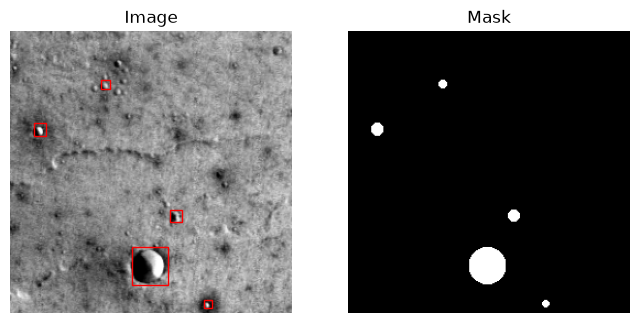

In [44]:
def make_mask(boxes):
    mask = np.zeros((256, 256), dtype=np.uint8)
    yy, xx = np.mgrid[0:256, 0:256]

    for x, y, w, h in boxes:
        cx = x + w / 2
        cy = y + h / 2
        r = max(w, h) / 2
        inside = (xx + 0.5 - cx) ** 2 + (yy + 0.5 - cy) ** 2 <= r ** 2
        mask[inside] = 1

    return mask


image_id = train_ids[2]
image = plt.imread(images_path / f"{image_id}.png")
mask = make_mask(data[image_id])

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(8, 4))

ax1.imshow(image, cmap="gray")
for x, y, w, h in data[image_id]:
    ax1.add_patch(Rectangle((x, y), w, h, fill=False, edgecolor="red", linewidth=1))
ax1.set_title("Image")
ax1.axis("off")

ax2.imshow(mask, cmap="gray")
ax2.set_title("Mask")
ax2.axis("off")

plt.show()

**Test:** one 20×20 box at (10, 10) should become a circle with center (20, 20) and radius 10. No boxes should give an empty mask.

- Box: top-left corner at x = 10, y = 10; 20 pixels wide and 20 pixels tall
- Expected center: (10 + 20/2, 10 + 20/2) = **(20, 20)**
- Expected radius: 20/2 = **10**
- Expected approximate area = **316**

In [45]:
# Test: one 20x20 box at (10, 10) -> circle with center (20, 20) and radius 10
mask = make_mask([(10, 10, 20, 20)])

assert mask.shape == (256, 256)
assert mask[20, 20] == 1                      # center is crater
assert mask[10, 10] == 0                      # box corner is outside the circle
assert mask[100, 100] == 0                    # far away is ground
assert abs(mask.sum() - 3.14 * 10**2) < 15    # area close to pi * r^2
assert make_mask([]).sum() == 0               # no boxes -> empty mask

print("make_mask tests passed")

make_mask tests passed


## Dataset and loaders

`CraterDataset` is used by the three mask models (MLP, CNN and U-Net). Faster R-CNN and DINOv3 need different inputs, so they get their own dataset classes later.

It gives one (image, mask) pair at a time:
- the image is loaded as grayscale and scaled to 0–1
- the mask is made with `make_mask` from that image's boxes

Both come out with shape (1, 256, 256): single channel and 256x256 pixels.

The loaders give batches of 16, a common default for full 256x256 images that fits in easily in GPU memory.

In [47]:
class CraterDataset(Dataset):
    def __init__(self, image_ids):
        self.image_ids = image_ids

    def __len__(self):
        return len(self.image_ids)

    def __getitem__(self, i):
        image_id = self.image_ids[i]

        image = Image.open(images_path / f"{image_id}.png").convert("L")
        image = torch.tensor(np.array(image), dtype=torch.float32) / 255.0
        image = image.unsqueeze(0)

        mask = make_mask(data[image_id])
        mask = torch.tensor(mask, dtype=torch.float32).unsqueeze(0)

        return image, mask


train_set = CraterDataset(train_ids)
val_set = CraterDataset(val_ids)
test_set = CraterDataset(test_ids)

train_loader = DataLoader(train_set, batch_size=16, shuffle=True)
val_loader = DataLoader(val_set, batch_size=16, shuffle=False)
test_loader = DataLoader(test_set, batch_size=16, shuffle=False)

images, masks = next(iter(train_loader))
print(images.shape)
print(masks.shape)

torch.Size([16, 1, 256, 256])
torch.Size([16, 1, 256, 256])


## Scoring Functions

We use two different scoring method:
- **Pixel IoU** (only for the mask models): overlap pixels ÷ union pixels between the predicted mask and the true mask, summed over all images.
- **Per-crater precision, recall and F1** (for every model): this is what matters for the rover, and it's the only score that can compare all models together.

Functions:
- `get_true_boxes`: turns the (x, y, w, h) labels into (x1, y1, x2, y2) boxes.
- `count_matches`: a predicted box finds a true crater if their box IoU is at least 0.5.
- `mask_to_boxes`: For making each connected blob in the mask models to become a one box
- `get_scores`: compute precision, recall and F1 from the counts, over all images.

In [48]:
def get_true_boxes(image_id):
    boxes = [[x, y, x + w, y + h] for x, y, w, h in data[image_id] if w > 0 and h > 0]
    return torch.tensor(boxes, dtype=torch.float32).reshape(-1, 4)


def count_matches(pred_boxes, true_boxes, iou_threshold=0.5):
    if len(pred_boxes) == 0 or len(true_boxes) == 0:
        return 0

    ious = box_iou(pred_boxes, true_boxes)
    matches = 0
    for i in range(len(pred_boxes)):
        j = ious[i].argmax()
        if ious[i, j] >= iou_threshold:
            matches += 1
            ious[:, j] = -1  # this real crater is taken
    return matches


def mask_to_boxes(pred_mask):
    labeled, n = ndimage.label(pred_mask)
    boxes = []
    for ys, xs in ndimage.find_objects(labeled):
        boxes.append([xs.start, ys.start, xs.stop, ys.stop])
    return torch.tensor(boxes, dtype=torch.float32).reshape(-1, 4)


def get_scores(tp, n_pred, n_true):
    precision = tp / n_pred if n_pred > 0 else 0.0
    recall = tp / n_true
    f1 = 2 * precision * recall / (precision + recall) if precision + recall > 0 else 0.0
    return precision, recall, f1

## Baselines: MLP and CNN


Two simple models for us to see how much the stronger models below improves. Both take a (batch, 1, 256, 256) image and output one crater score per pixel, shape (batch, 1, 256, 256).

- **MLP**: 525,568 parameters
- **CNN**: 166,593 parameters

In [49]:
class PatchMLP(nn.Module):
    def __init__(self, patch=16):
        super().__init__()
        self.patch = patch
        self.mlp = nn.Sequential(
            nn.Linear(patch * patch, 512),
            nn.ReLU(),
            nn.Linear(512, 512),
            nn.ReLU(),
            nn.Linear(512, patch * patch),
        )

    def forward(self, x):
        b, p = x.shape[0], self.patch
        n = 256 // p

        # cut each image into 16 x 16 patches, flatten each patch
        x = x.view(b, n, p, n, p).permute(0, 1, 3, 2, 4).reshape(b * n * n, p * p)
        x = self.mlp(x)
        # put the patches back together into a 256 x 256 map
        x = x.view(b, n, n, p, p).permute(0, 1, 3, 2, 4).reshape(b, 1, 256, 256)
        return x


def conv_block(in_channels, out_channels):
    return nn.Sequential(
        nn.Conv2d(in_channels, out_channels, kernel_size=3, padding=1),
        nn.ReLU(),
        nn.Conv2d(out_channels, out_channels, kernel_size=3, padding=1),
        nn.ReLU(),
    )


class PlainCNN(nn.Module):
    def __init__(self):
        super().__init__()
        self.layers = nn.Sequential(
            conv_block(1, 32),    # (32, 256, 256)
            conv_block(32, 64),   # (64, 256, 256)
            conv_block(64, 64),   # (64, 256, 256)
            conv_block(64, 32),   # (32, 256, 256)
            nn.Conv2d(32, 1, kernel_size=1),  # (1, 256, 256)
        )

    def forward(self, x):
        return self.layers(x)

## Baseline Results

The code for the baselines is not shown to avoid crowding this file. These models are only meant to show how much we can improve.

In [54]:
# Validation and test results of the two baselines, read from their saved files
rows = []
for name, folder in [("MLP", "src/mlp/01-baseline"), ("CNN", "src/cnn/01-baseline")]:
    history = json.loads(Path(folder, "history.json").read_text())
    test = json.loads(Path(folder, "test_scores.json").read_text())

    best_epoch = history["val_iou"].index(max(history["val_iou"]))   # epoch with the highest val IoU
    rows.append({
        "Model": name,
        "Best epoch": best_epoch + 1,
        "Cutoff": test["cutoff"],
        "Val IoU": history["val_iou"][best_epoch],
        "Test IoU": test["pixel_iou_0.5"],
        "Test precision": test["precision"],
        "Test recall": test["recall"],
        "Test F1": test["f1"],
    })

pd.DataFrame(rows).set_index("Model").round(3)

,Best epoch,Cutoff,Val IoU,Test IoU,Test precision,Test recall,Test F1
Model,,,,,,,
MLP,6,0.5,0.181,0.176,0.067,0.316,0.110
CNN,7,0.5,0.221,0.215,0.031,0.634,0.059


**Baseline results.** As expected, both baselines are very weak.
- The CNN has a better pixel IoU than the MLP (0.22 vs 0.18), but a worse per-crater F1 (0.06 vs 0.11).
- The MLP only sees one 16×16 patch at a time, and the CNN only a 17×17 area, so neither can see a whole crater.

This is why the next model, U-Net will be a improvement. Each pixel will be able to see a much larger area.

## Advanced Model 1: U-Net (Trained from scratch)


U-Net works with two half:

- **Shrinking half:** convolutional block with max pooling. 256x256 image becomes 32x32. Each pooling halves the size. Therefore, deeper leayers can see much larger area of the image, which is enough to see a whole crater. This is the biggest improvement from the baselines.
- **Growing half:** transposed convolutions bring it back up to 256×256. Shrinking an image and growing it back makes the model forget some details. Therefore, we use a skip connection to bring fine details back in.

- **Input:** (batch, 1, 256, 256) grayscale image
- **Output:** (batch, 1, 256, 256) crater scores (logits), one per pixel
- **Parameters:** 1,925,025


In [57]:
def conv_block(in_channels, out_channels):
    return nn.Sequential(
        nn.Conv2d(in_channels, out_channels, kernel_size=3, padding=1),
        nn.ReLU(),
        nn.Conv2d(out_channels, out_channels, kernel_size=3, padding=1),
        nn.ReLU(),
    )


class UNet(nn.Module):
    def __init__(self):
        super().__init__()
        self.pool = nn.MaxPool2d(2)

        # shrinking half
        self.down1 = conv_block(1, 32)      # (32, 256, 256)
        self.down2 = conv_block(32, 64)     # (64, 128, 128)
        self.down3 = conv_block(64, 128)    # (128, 64, 64)
        self.bottom = conv_block(128, 256)  # (256, 32, 32)

        # growing half
        self.up3 = nn.ConvTranspose2d(256, 128, kernel_size=2, stride=2)  # (128, 64, 64)
        self.conv3 = conv_block(256, 128)
        self.up2 = nn.ConvTranspose2d(128, 64, kernel_size=2, stride=2)   # (64, 128, 128)
        self.conv2 = conv_block(128, 64)
        self.up1 = nn.ConvTranspose2d(64, 32, kernel_size=2, stride=2)    # (32, 256, 256)
        self.conv1 = conv_block(64, 32)

        self.out = nn.Conv2d(32, 1, kernel_size=1)  # (1, 256, 256)

    def forward(self, x):
        d1 = self.down1(x)
        d2 = self.down2(self.pool(d1))
        d3 = self.down3(self.pool(d2))
        b = self.bottom(self.pool(d3))

        u3 = self.conv3(torch.cat([self.up3(b), d3], dim=1))
        u2 = self.conv2(torch.cat([self.up2(u3), d2], dim=1))
        u1 = self.conv1(torch.cat([self.up1(u2), d1], dim=1))
        return self.out(u1)

model = UNet().to(device)
print(sum(p.numel() for p in model.parameters()))

# quick check: one batch in, output should be the same shape as the masks
with torch.no_grad():
    out = model(images.to(device))
print(out.shape)

1925025
torch.Size([16, 1, 256, 256])


## Training the U-Net

- **Loss:** `BCEWithLogitsLoss` with `pos_weight=10`. The weighted version is for avoiding the class imbalance problem since only 2% of the pixels are craters in each image.
- **Optimizer:** Adam, learning rate 0.001, the default.
- **Cosine schedule:** the learning rate goes smoothly from 0.001 down to 0 over 15 epochs.
- **15 epochs**, batch size 16.
- **Cutoff tuning:** For each pixel, the model outputs a probability. The cutoff decides which pixels count as a crater. After each epoch we try 0.5, 0.6, 0.7, 0.8 and 0.9 on validation and keep the best.

Note: The model is saved only when the validation IoU is the best so far.

In [60]:
run_name = "02-cosine-lr"
# Here we use a new folder, /src-submit. The training that was already run saved its output to /src, 
# so the code that reads the logs uses /src.run_dir = Path("src-submit/unet") / run_name
run_dir.mkdir(parents=True, exist_ok=True)

model = UNet().to(device)
loss_fn = nn.BCEWithLogitsLoss(pos_weight=torch.tensor([10.0], device=device))
optimizer = torch.optim.Adam(model.parameters(), lr=1e-3)

epochs = 15
scheduler = torch.optim.lr_scheduler.CosineAnnealingLR(optimizer, T_max=epochs)

In [61]:
cutoffs = [0.5, 0.6, 0.7, 0.8, 0.9]


def evaluate(model, loader):
    model.eval()
    total_loss, n = 0.0, 0
    intersection = {c: 0 for c in cutoffs}
    union = {c: 0 for c in cutoffs}

    with torch.no_grad():
        for images, masks in loader:
            images, masks = images.to(device), masks.to(device)

            outputs = model(images)
            total_loss += loss_fn(outputs, masks).item() * len(images)
            n += len(images)

            probs = torch.sigmoid(outputs)
            for c in cutoffs:
                preds = (probs > c).float()
                intersection[c] += (preds * masks).sum().item()
                union[c] += ((preds + masks) > 0).sum().item()

    ious = {c: intersection[c] / union[c] for c in cutoffs}
    best_cutoff = max(ious, key=ious.get)
    return total_loss / n, ious[best_cutoff], best_cutoff

In [ ]:
history = {"train_loss": [], "val_loss": [], "val_iou": [], "best_cutoff": [], "lr": []}
best_iou = 0.0

for epoch in range(epochs):
    model.train()
    running_loss, n = 0.0, 0
    start = time.time()

    for images, masks in progress:
        images, masks = images.to(device), masks.to(device)

        outputs = model(images)
        loss = loss_fn(outputs, masks)

        optimizer.zero_grad()
        loss.backward()
        optimizer.step()

        running_loss += loss.item() * len(images)
        n += len(images)
        progress.set_postfix(loss=f"{running_loss / n:.4f}")

    train_loss = running_loss / n
    val_loss, val_iou, cutoff = evaluate(model, val_loader)
    lr = optimizer.param_groups[0]["lr"]
    scheduler.step()

    history["train_loss"].append(train_loss)
    history["val_loss"].append(val_loss)
    history["val_iou"].append(val_iou)
    history["best_cutoff"].append(cutoff)
    history["lr"].append(lr)
    (run_dir / "history.json").write_text(json.dumps(history))

    saved = ""
    if val_iou > best_iou:
        best_iou = val_iou
        torch.save(model.state_dict(), run_dir / "unet.pt")
        saved = " (saved)"

    print(f"Epoch {epoch + 1}: train loss {train_loss:.4f} | val loss {val_loss:.4f}, "
          f"val IoU {val_iou:.4f} at cutoff {cutoff} | lr {lr:.6f} | {time.time() - start:.0f}s{saved}")

## U-Net Results:

The code above does not have any output cell because the results will be shown below from the saved logs.

In [69]:
# U-Net results, read from its saved files
folder = Path("src/unet/02-cosine-lr")
history = json.loads((folder / "history.json").read_text())
val_craters = json.loads((folder / "crater_scores.json").read_text())   # val precision/recall/F1 per cutoff
test = json.loads((folder / "test_scores.json").read_text())

best_epoch = history["val_iou"].index(max(history["val_iou"]))   # epoch with the highest val IoU
cutoff = str(test["cutoff"])                                      # crater cutoff chosen on validation (0.9)

rows = [
    {"Set": "Validation",
     "Pixel IoU": history["val_iou"][best_epoch],
     "Precision": val_craters[cutoff]["precision"],
     "Recall": val_craters[cutoff]["recall"],
     "F1": val_craters[cutoff]["f1"]},
    {"Set": "Test",
     "Pixel IoU": test["pixel_iou_0.8"],
     "Precision": test["precision"],
     "Recall": test["recall"],
     "F1": test["f1"]},
]

print(f"Best epoch: {best_epoch + 1} of {len(history['val_iou'])}, crater cutoff: {cutoff}")
pd.DataFrame(rows).set_index("Set").round(4)

Best epoch: 10 of 15, crater cutoff: 0.9


,Pixel IoU,Precision,Recall,F1
Set,,,,
Validation,0.5188,0.4980,0.6996,0.5818
Test,0.5115,0.4811,0.7029,0.5712


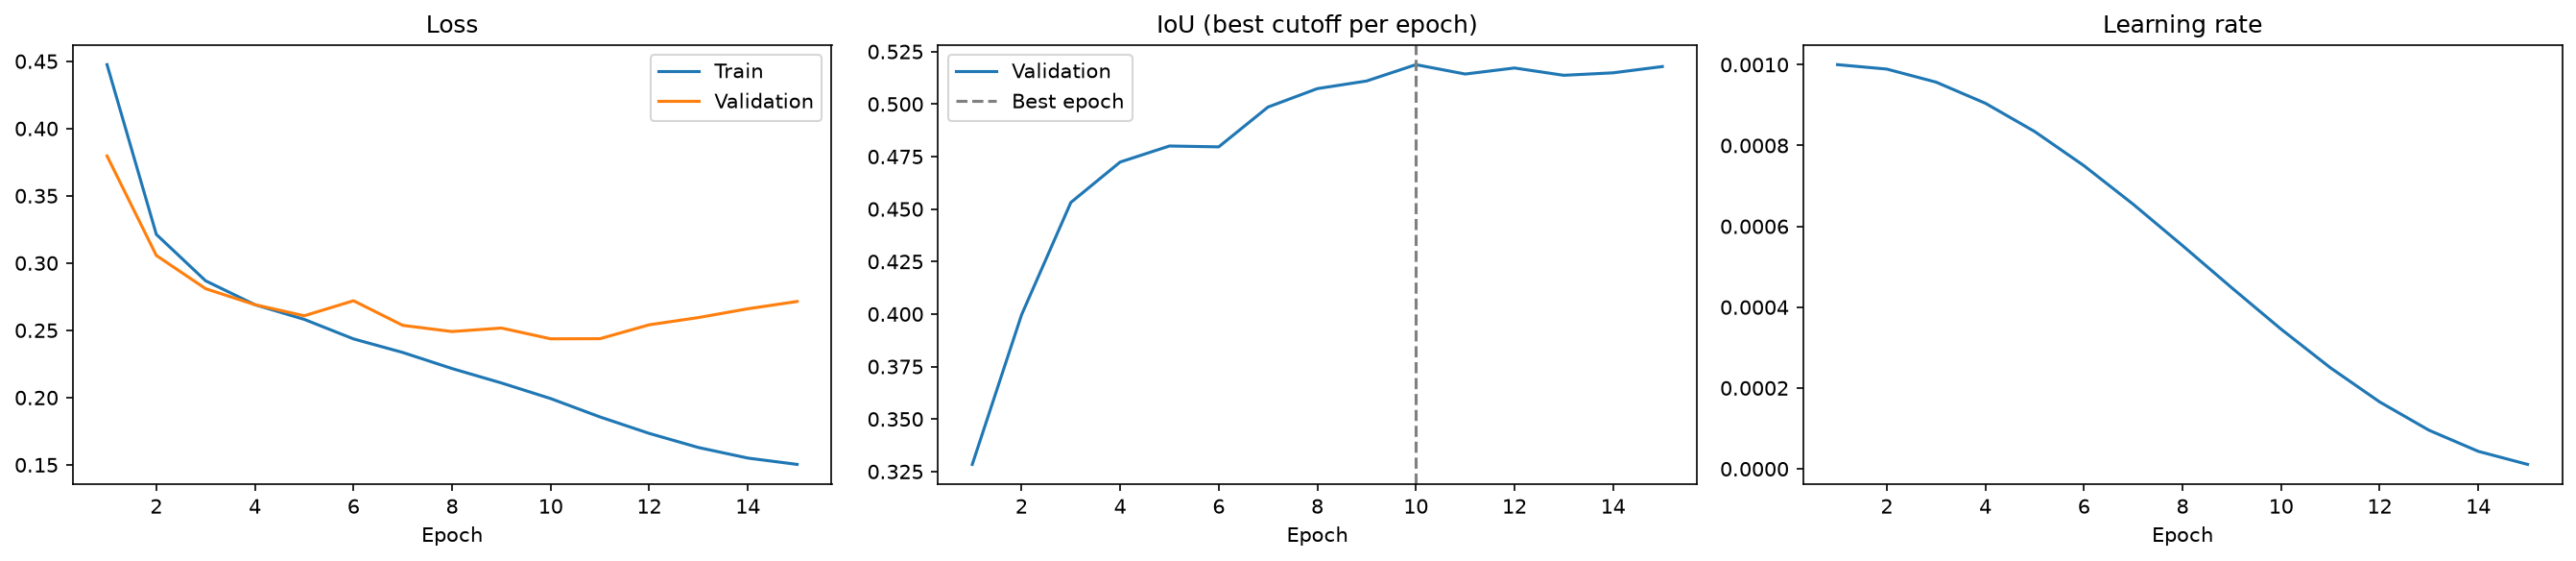

## U-Net Results:

- **Overfit:** We can see that after around epoch 10, even though train loss continues to go down, the validation loss starts increasing. This is a sign of overfitting. Therefore, keeping only the best epoch protected us against saving a model with higher validation loss.

- **Crater Cutoff:** 0.9. A higher cutoff keeps only pixels where the model is very sure about it, which removes most of the false-alarm blobs.

- **Test F1 0.57 vs validation F1 0.58:** Almost the same, so the cutoff choice wasn't arbitrary on the validation set.

- **Better than the baselines:** F1 0.57 vs 0.11 (MLP) and 0.06 (CNN). As mentioned above, seeing a larger area makes a difference.

- **Weakness:** Recall is 0.70, so it still misses 30% of the craters, while precision being 0.48 means half of the predictred craters are false alarms.

## Advanced Model 2: Faster R-CNN (fine-tuned)

> **Note:** Faster R-CNN predicts boxes directly, not masks. Therefore, it needs its own dataset class.

- **Channel fix:** The model was pretrained on color images, so it expects 3 channels. We copy our grayscale images into 3 channels.
- **Boxes as (x1, y1, x2, y2):** Unlike the other models, torchvision expects this format instead of (x, y, w, h), so we convert them. Boxes with zero width or height are ignored.
- **New labels (0, 1):** 1 means crater, 0 means background.
- **`collate_fn`:** Since each image has a different number of craters, we cannot stack the targets into one tensor. Instead, we keep them as a list.

### Model

Faster R-CNN with a ResNet-50 + FPN backbone, pretrained on COCO. We fine-tune it as follows:

- a) The pretrained box classifier is replaced with a new one for only 2 classes.
- b) By default, torchvision resizes each image so its short side is 800 pixels. However, for faster training and less memory usage, we keep them at 256×256.
- c) Parameters: **41,299,161**

> **Note:** Since this model is much bigger (41M parameters), we use a batch size of 8 instead of 16.

At the end, we check whether the converted boxes still sit on the craters.

In [72]:
class CraterDetectionDataset(Dataset):
    def __init__(self, image_ids):
        self.image_ids = image_ids

    def __len__(self):
        return len(self.image_ids)

    def __getitem__(self, i):
        image_id = self.image_ids[i]

        image = Image.open(images_path / f"{image_id}.png").convert("RGB")
        image = torch.tensor(np.array(image), dtype=torch.float32).permute(2, 0, 1) / 255.0

        boxes = [[x, y, x + w, y + h] for x, y, w, h in data[image_id] if w > 0 and h > 0]
        boxes = torch.tensor(boxes, dtype=torch.float32).reshape(-1, 4)
        labels = torch.ones(len(boxes), dtype=torch.int64)

        return image, {"boxes": boxes, "labels": labels}

8 torch.Size([3, 256, 256])
{'boxes': tensor([[234., 166., 242., 174.],
        [ 39., 155.,  48., 165.],
        [195.,  96., 204., 106.],
        [229., 246., 237., 254.],
        [190., 232., 200., 242.]]), 'labels': tensor([1, 1, 1, 1, 1])}


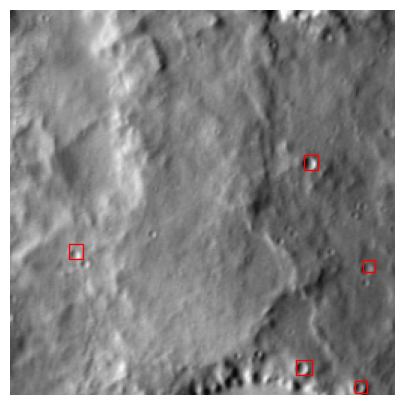

In [78]:
def collate_fn(batch):
    return tuple(zip(*batch))


train_set = CraterDetectionDataset(train_ids)
val_set = CraterDetectionDataset(val_ids)
test_set = CraterDetectionDataset(test_ids)

train_loader = DataLoader(train_set, batch_size=8, shuffle=True, collate_fn=collate_fn)
val_loader = DataLoader(val_set, batch_size=8, shuffle=False, collate_fn=collate_fn)
test_loader = DataLoader(test_set, batch_size=8, shuffle=False, collate_fn=collate_fn)

images, targets = next(iter(train_loader))
print(len(images), images[0].shape)
print(targets[0])

# check that the converted boxes still sit on the craters
fig, ax = plt.subplots(figsize=(5, 5))
ax.imshow(images[0].permute(1, 2, 0))
for x1, y1, x2, y2 in targets[0]["boxes"]:
    ax.add_patch(Rectangle((x1, y1), x2 - x1, y2 - y1, fill=False, edgecolor="red", linewidth=1))
ax.axis("off")
plt.show()

## Training the Faster R-CNN

- **Optimizer:** SGD, learning rate 0.005, momentum 0.9, weight decay 0.0005. These are torchvision's standard values for fine-tuning Faster R-CNN. Weight decay is a small penalty on large weights, to reduce overfitting.
- **Loss:** The sum of the model's 4 losses.
- **Cosine schedule:** the learning rate goes smoothly from 0.005 down to 0 over 15 epochs.
- **15 epochs**, batch size 8.
- **Cutoff tuning:** For each box, the model outputs a score. The cutoff decides which boxes count as a crater. After each epoch we try 0.3, 0.5, 0.7, 0.8 and 0.9 on validation and keep the best.

Note: The model is saved only when the validation F1 is the best so far.

In [79]:
from torchvision.ops import box_iou

cutoffs = [0.3, 0.5, 0.7, 0.8, 0.9]

def count_matches(pred_boxes, true_boxes, iou_threshold=0.5):
    if len(pred_boxes) == 0 or len(true_boxes) == 0:
        return 0

    ious = box_iou(pred_boxes, true_boxes)
    matches = 0
    for i in range(len(pred_boxes)):
        j = ious[i].argmax()
        if ious[i, j] >= iou_threshold:
            matches += 1
            ious[:, j] = -1  # this real crater is taken
    return matches


def evaluate(model, loader):
    model.eval()
    tp = {c: 0 for c in cutoffs}
    n_pred = {c: 0 for c in cutoffs}
    n_true = 0

    with torch.no_grad():
        for images, targets in loader:
            images = [img.to(device) for img in images]
            outputs = model(images)

            for out, target in zip(outputs, targets):
                true_boxes = target["boxes"].to(device)
                n_true += len(true_boxes)

                for c in cutoffs:
                    pred_boxes = out["boxes"][out["scores"] > c]
                    n_pred[c] += len(pred_boxes)
                    tp[c] += count_matches(pred_boxes, true_boxes)

    results = {}
    for c in cutoffs:
        precision = tp[c] / n_pred[c] if n_pred[c] > 0 else 0.0
        recall = tp[c] / n_true
        f1 = 2 * precision * recall / (precision + recall) if precision + recall > 0 else 0.0
        results[c] = {"precision": precision, "recall": recall, "f1": f1}

    best_cutoff = max(results, key=lambda c: results[c]["f1"])
    return results[best_cutoff], best_cutoff

In [80]:
run_name = "01-baseline"
run_dir = Path("src-submit/faster-rcnn") / run_name
run_dir.mkdir(parents=True, exist_ok=True)

optimizer = torch.optim.SGD(model.parameters(), lr=0.005, momentum=0.9, weight_decay=0.0005)

epochs = 15
scheduler = torch.optim.lr_scheduler.CosineAnnealingLR(optimizer, T_max=epochs)

In [ ]:
history = {"train_loss": [], "val_precision": [], "val_recall": [], "val_f1": [], "best_cutoff": [], "lr": []}
best_f1 = 0.0

for epoch in range(epochs):
    model.train()
    running_loss, n = 0.0, 0
    start = time.time()

    progress = tqdm(train_loader, desc=f"Epoch {epoch + 1}/{epochs}", mininterval=1.0)
    for images, targets in progress:
        images = [img.to(device) for img in images]
        targets = [{k: v.to(device) for k, v in t.items()} for t in targets]

        loss_dict = model(images, targets)
        loss = sum(loss_dict.values())

        optimizer.zero_grad()
        loss.backward()
        optimizer.step()

        running_loss += loss.item() * len(images)
        n += len(images)
        progress.set_postfix(loss=f"{running_loss / n:.4f}")

    train_loss = running_loss / n
    val, cutoff = evaluate(model, val_loader)
    lr = optimizer.param_groups[0]["lr"]
    scheduler.step()

    history["train_loss"].append(train_loss)
    history["val_precision"].append(val["precision"])
    history["val_recall"].append(val["recall"])
    history["val_f1"].append(val["f1"])
    history["best_cutoff"].append(cutoff)
    history["lr"].append(lr)
    (run_dir / "history.json").write_text(json.dumps(history))

    saved = ""
    if val["f1"] > best_f1:
        best_f1 = val["f1"]
        torch.save(model.state_dict(), run_dir / "model.pt")
        saved = " (saved)"

    print(f"Epoch {epoch + 1}: train loss {train_loss:.4f} | val precision {val['precision']:.3f}, "
          f"recall {val['recall']:.3f}, F1 {val['f1']:.3f} at cutoff {cutoff} | lr {lr:.6f} | "
          f"{time.time() - start:.0f}s{saved}")

## Faster R-CNN Results:

The code above does not have any output cell because the results will be shown below from the saved logs.

In [81]:
# Faster R-CNN results, read from its saved files
folder = Path("src/faster-rcnn/01-baseline")
history = json.loads((folder / "history.json").read_text())
test = json.loads((folder / "test_scores.json").read_text())

best_epoch = history["val_f1"].index(max(history["val_f1"]))   # epoch with the highest val F1

rows = [
    {"Set": "Validation",
     "Precision": history["val_precision"][best_epoch],
     "Recall": history["val_recall"][best_epoch],
     "F1": history["val_f1"][best_epoch]},
    {"Set": "Test",
     "Precision": test["precision"],
     "Recall": test["recall"],
     "F1": test["f1"]},
]

print(f"Best epoch: {best_epoch + 1} of {len(history['val_f1'])}, cutoff: {history['best_cutoff'][best_epoch]}")
pd.DataFrame(rows).set_index("Set").round(4)

Best epoch: 15 of 15, cutoff: 0.8


,Precision,Recall,F1
Set,,,
Validation,0.7935,0.7974,0.7954
Test,0.7949,0.8029,0.7989


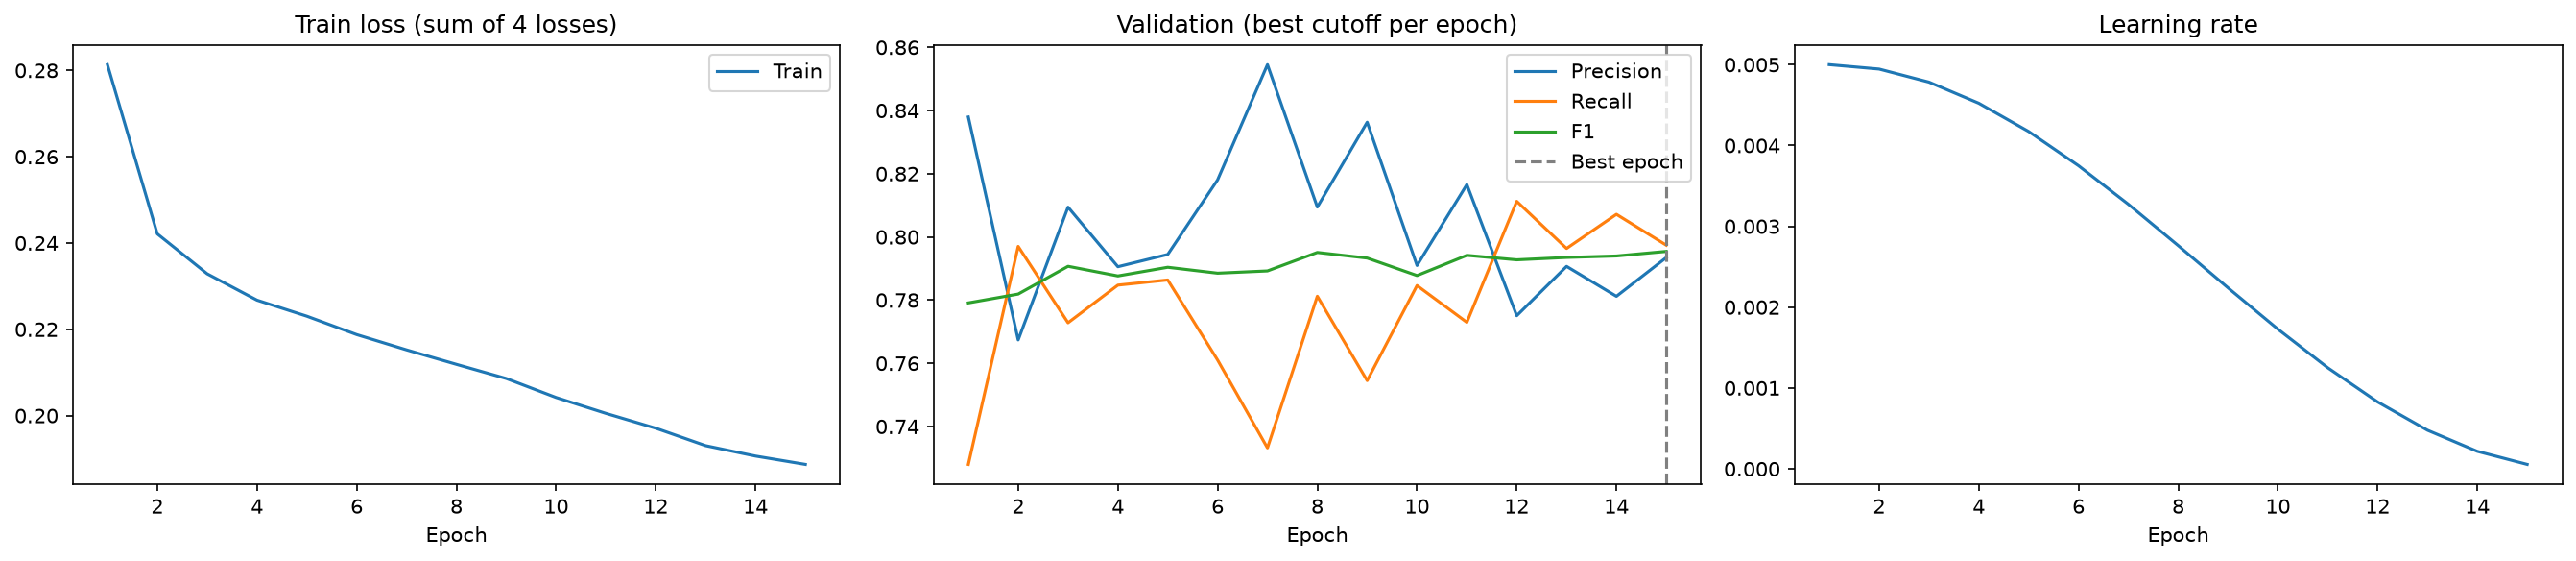

## Faster R-CNN Results:

Among the main detectors, Faster R-CNN is clearly the winner. It has an $F_1$ score of 0.80, with very close precision and recall scores.

- **Box Cutoff:** 0.8. A higher cutoff keeps only boxes where the model is very sure about it, while 0.8 still keeps enough boxes to find most of the craters.

- **Test F1 0.80 vs validation F1 0.80:** Almost the same, so the cutoff choice wasn't arbitrary on the validation set.

- **Better than the U-Net:** F1 0.80 vs 0.57 (U-Net). It predicts boxes directly, instead of turning pixel blobs into boxes, and it starts from a model that was already trained on many images.

- **Weakness:** Recall is 0.80, so it still misses 20% of the craters, while precision being 0.79 means about 1 in 5 of the predicted craters are false alarms.